# Phase 3 — Traditional Models: Logistic Regression and Random Forest

**Follows:** `03_feature_selection.ipynb` (30 selected features).

**Scope:** train two classic models, first with sensible defaults, then tuned with Optuna on the 2018 validation year.

| Model | Why it's here |
|---|---|
| Logistic regression | The reference point. Fast and interpretable. A complex model has to clearly beat it to justify itself |
| Random Forest | The classic non-linear model. It captures interactions without boosting, so it shows how much of CatBoost's edge comes from boosting itself |

**Protocol (shared by every model in this project, see `src/evaluation.py`):**
- Fit on undersampled **training** data (≤2017); score on the full **2018 validation** year at its real fraud rate.
- Headline metric: **PR-AUC**. Also recall at 50% precision, and precision/recall when flagging the top 0.1% of transactions (an alert budget of about 1,700 a year).
- Decision threshold chosen on validation (max F1) and stored for the final test.
- **The 2019 test set is not loaded here.**

## 0. Setup

In [1]:
import sys, json, time, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import optuna
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score

from src.data import PROJECT_ROOT
from src.modeling import (TARGET, load_split, feature_sets, undersample,
                          linear_preprocessor, tree_matrix)
from src.evaluation import evaluate, compare, plot_pr_curves

sns.set_style("whitegrid")
optuna.logging.set_verbosity(optuna.logging.WARNING)
SEED = 0
MODELS_DIR = PROJECT_ROOT / "models"; MODELS_DIR.mkdir(exist_ok=True)
REPORTS_DIR = PROJECT_ROOT / "reports"

FEATURES = feature_sets()["selected"]
train = load_split("train", FEATURES + ["year"])
val = load_split("val", FEATURES)
y_val = val[TARGET].to_numpy()
print(f"{len(FEATURES)} features | train {len(train):,} rows | val {len(val):,} rows, {y_val.sum():,} frauds")

C:\Users\001\.conda\envs\fraud-detection\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


30 features | train 20,604,847 rows | val 1,721,615 rows, 2,491 frauds


In [2]:
def training_sample(neg_per_pos, start_year=1991, seed=SEED):
    """Undersampled training data. `start_year` drops early years: fraud patterns
    drift, so older data may hurt more than it helps. That's a tuning choice."""
    return undersample(train[train["year"] >= start_year], neg_per_pos, seed=seed)

results, val_scores, best_params = {}, {}, {}

## 1. Logistic regression

### 1.1 Baseline (defaults)

Standard choices with no tuning: L2 penalty, C = 1, `class_weight="balanced"`, all training years, 1 fraud : 10 non-frauds. Inputs are median-imputed (plus a missing-value flag), standardized and one-hot encoded (`src/modeling.linear_preprocessor`).

In [3]:
def fit_logreg(C=1.0, penalty="l2", class_weight="balanced", neg_per_pos=10, start_year=1991):
    s = training_sample(neg_per_pos, start_year)
    pre = linear_preprocessor(FEATURES)
    X = pre.fit_transform(s[FEATURES])
    if penalty == "l1":
        clf = LogisticRegression(l1_ratio=1, solver="liblinear", C=C, class_weight=class_weight, max_iter=1000)
    else:
        clf = LogisticRegression(l1_ratio=0, solver="lbfgs", C=C, class_weight=class_weight, max_iter=2000)
    clf.fit(X, s[TARGET])
    return pre, clf

def score_logreg(pre, clf, df):
    return clf.predict_proba(pre.transform(df[FEATURES]))[:, 1]

t0 = time.time()
lr_base = fit_logreg()
val_scores["LogReg (baseline)"] = score_logreg(*lr_base, val)
results["LogReg (baseline)"] = evaluate(y_val, val_scores["LogReg (baseline)"])
print(f"{time.time() - t0:.0f}s")
compare(results)

12s


,pr_auc,roc_auc,recall@precision0.5,precision@top0.1%,recall@top0.1%,threshold,precision@threshold,recall@threshold,alerts@threshold
LogReg (baseline),0.1372,0.9826,0.0024,0.241,0.1666,0.9829,0.1938,0.4183,5377.0


### 1.2 Tuning with Optuna

🎯 **Goal:** find the best settings for a linear model, judged only on the 2018 validation year.

💡 **What's searched, and why:**
- `C`: regularization strength, on a log scale.
- `penalty`: L1 (sparse) or L2 (shrinks all coefficients).
- `class_weight`: balanced or none. The sample is already 1:N, so extra re-weighting may or may not help.
- `neg_per_pos`: how many non-frauds per fraud to train on. More shows more normal behavior but dilutes fraud.
- `start_year`: whether old years help or hurt, given that fraud patterns drift.

Optuna's TPE sampler learns from earlier trials which regions look promising, so 25 trials go further than a 25-point grid. **Caveat:** each trial is scored on validation, so the best score is slightly optimistic. The untouched 2019 test year gives the honest number.

In [4]:
def lr_objective(trial):
    params = dict(
        C=trial.suggest_float("C", 1e-4, 10, log=True),
        penalty=trial.suggest_categorical("penalty", ["l1", "l2"]),
        class_weight=trial.suggest_categorical("class_weight", ["balanced", None]),
        neg_per_pos=trial.suggest_categorical("neg_per_pos", [5, 10, 20, 50]),
        start_year=trial.suggest_categorical("start_year", [1991, 2000, 2005, 2010]),
    )
    pre, clf = fit_logreg(**params)
    return average_precision_score(y_val, score_logreg(pre, clf, val))

t0 = time.time()
lr_study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
lr_study.enqueue_trial(dict(C=1.0, penalty="l2", class_weight="balanced", neg_per_pos=10, start_year=1991))  # baseline as trial 0
lr_study.optimize(lr_objective, n_trials=25)
print(f"25 trials in {time.time() - t0:.0f}s | best val PR-AUC {lr_study.best_value:.4f}")
best_params["logreg"] = lr_study.best_params
lr_study.best_params

25 trials in 3732s | best val PR-AUC 0.1521


{'C': 0.0026239297813109783,
 'penalty': 'l2',
 'class_weight': 'balanced',
 'neg_per_pos': 50,
 'start_year': 1991}

In [5]:
lr_trials = lr_study.trials_dataframe()[["number", "value", "params_C", "params_penalty",
                                          "params_class_weight", "params_neg_per_pos", "params_start_year"]]
lr_trials.sort_values("value", ascending=False).head(8)

,number,value,params_C,params_penalty,params_class_weight,params_neg_per_pos,params_start_year
24,24,0.152126,0.002624,l2,balanced,50,1991
23,23,0.151428,0.016333,l2,balanced,50,1991
22,22,0.148885,0.026065,l2,balanced,50,1991
21,21,0.148470,0.027050,l2,balanced,50,1991
19,19,0.147314,0.033974,l2,balanced,50,1991
20,20,0.141326,0.194730,l2,balanced,50,1991
18,18,0.140915,0.468378,l2,balanced,50,1991
15,15,0.137342,1.194938,l2,balanced,10,1991


In [6]:
lr_tuned = fit_logreg(**best_params["logreg"])
val_scores["LogReg (tuned)"] = score_logreg(*lr_tuned, val)
results["LogReg (tuned)"] = evaluate(y_val, val_scores["LogReg (tuned)"])
compare(results)

,pr_auc,roc_auc,recall@precision0.5,precision@top0.1%,recall@top0.1%,threshold,precision@threshold,recall@threshold,alerts@threshold
LogReg (baseline),0.1372,0.9826,0.0024,0.2410,0.1666,0.9829,0.1938,0.4183,5377.0
LogReg (tuned),0.1521,0.9825,0.0024,0.2515,0.1738,0.9787,0.2104,0.4287,5076.0


## 2. Random Forest

### 2.1 Baseline (defaults)

300 trees, scikit-learn's default settings otherwise (fully grown trees, `sqrt` features per split), all training years, 1:10 sample. Trees don't need scaling or one-hot encoding, so categoricals go in as integer codes (`src/modeling.tree_matrix`).

In [7]:
def fit_rf(max_depth=None, min_samples_leaf=1, max_features="sqrt", class_weight=None,
           neg_per_pos=10, start_year=1991, n_estimators=300):
    s = training_sample(neg_per_pos, start_year)
    rf = RandomForestClassifier(n_estimators=n_estimators, max_depth=max_depth,
                                min_samples_leaf=min_samples_leaf, max_features=max_features,
                                class_weight=class_weight, n_jobs=-1, random_state=SEED)
    return rf.fit(tree_matrix(s, FEATURES), s[TARGET])

X_val_tree = tree_matrix(val, FEATURES)

t0 = time.time()
rf_base = fit_rf()
val_scores["RandomForest (baseline)"] = rf_base.predict_proba(X_val_tree)[:, 1]
results["RandomForest (baseline)"] = evaluate(y_val, val_scores["RandomForest (baseline)"])
print(f"{time.time() - t0:.0f}s")
compare(results)

33s


,pr_auc,roc_auc,recall@precision0.5,precision@top0.1%,recall@top0.1%,threshold,precision@threshold,recall@threshold,alerts@threshold
LogReg (baseline),0.1372,0.9826,0.0024,0.2410,0.1666,0.9829,0.1938,0.4183,5377.0
LogReg (tuned),0.1521,0.9825,0.0024,0.2515,0.1738,0.9787,0.2104,0.4287,5076.0
RandomForest (baseline),0.3476,0.9968,0.0518,0.4483,0.3099,0.6733,0.3807,0.4998,3270.0


### 2.2 Tuning with Optuna

💡 **What's searched:**
- `max_depth` and `min_samples_leaf`: how complex each tree may get. Fully grown trees on a 1:N sample tend to memorize individual frauds.
- `max_features`: how many features each split considers. Fewer means more diverse trees.
- `class_weight`: none or `balanced_subsample` (re-weighted inside each bootstrap sample).
- `neg_per_pos` and `start_year`: as for logistic regression.

The number of trees stays at 300 during the search. More trees never hurts a Random Forest, it only costs time, so it isn't worth tuning.

In [8]:
def rf_objective(trial):
    depth = trial.suggest_categorical("max_depth", [None, 12, 20, 30])
    params = dict(
        max_depth=depth,
        min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 50, log=True),
        max_features=trial.suggest_categorical("max_features", ["sqrt", 0.3, 0.5]),
        class_weight=trial.suggest_categorical("class_weight", [None, "balanced_subsample"]),
        neg_per_pos=trial.suggest_categorical("neg_per_pos", [5, 10, 20, 40]),
        start_year=trial.suggest_categorical("start_year", [1991, 2000, 2005, 2010]),
    )
    rf = fit_rf(**params)
    return average_precision_score(y_val, rf.predict_proba(X_val_tree)[:, 1])

t0 = time.time()
rf_study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
rf_study.enqueue_trial(dict(max_depth=None, min_samples_leaf=1, max_features="sqrt",
                            class_weight=None, neg_per_pos=10, start_year=1991))
rf_study.optimize(rf_objective, n_trials=25)
print(f"25 trials in {time.time() - t0:.0f}s | best val PR-AUC {rf_study.best_value:.4f}")
best_params["random_forest"] = rf_study.best_params
rf_study.best_params

25 trials in 2436s | best val PR-AUC 0.7072


{'max_depth': 30,
 'min_samples_leaf': 1,
 'max_features': 0.5,
 'class_weight': None,
 'neg_per_pos': 40,
 'start_year': 2010}

In [9]:
rf_trials = rf_study.trials_dataframe()[["number", "value", "params_max_depth", "params_min_samples_leaf",
                                          "params_max_features", "params_class_weight",
                                          "params_neg_per_pos", "params_start_year"]]
rf_trials.sort_values("value", ascending=False).head(8)

,number,value,params_max_depth,params_min_samples_leaf,params_max_features,params_class_weight,params_neg_per_pos,params_start_year
24,24,0.707199,30.0,1,0.5,None,40,2010
23,23,0.707199,30.0,1,0.5,None,40,2010
1,1,0.690653,12.0,4,0.5,None,40,2010
12,12,0.677164,12.0,2,0.5,None,40,2010
11,11,0.677164,12.0,2,0.5,None,40,2010
21,21,0.677164,12.0,2,0.5,None,40,2010
10,10,0.618347,12.0,11,0.5,None,40,2010
6,6,0.523653,30.0,2,0.3,None,40,2005


The final tuned forest uses 500 trees instead of 300. As noted above, more trees only make the averaging more stable.

In [10]:
t0 = time.time()
rf_tuned = fit_rf(**best_params["random_forest"], n_estimators=500)
val_scores["RandomForest (tuned)"] = rf_tuned.predict_proba(X_val_tree)[:, 1]
results["RandomForest (tuned)"] = evaluate(y_val, val_scores["RandomForest (tuned)"])
print(f"{time.time() - t0:.0f}s")
compare(results)

306s


,pr_auc,roc_auc,recall@precision0.5,precision@top0.1%,recall@top0.1%,threshold,precision@threshold,recall@threshold,alerts@threshold
LogReg (baseline),0.1372,0.9826,0.0024,0.2410,0.1666,0.9829,0.1938,0.4183,5377.0
LogReg (tuned),0.1521,0.9825,0.0024,0.2515,0.1738,0.9787,0.2104,0.4287,5076.0
RandomForest (baseline),0.3476,0.9968,0.0518,0.4483,0.3099,0.6733,0.3807,0.4998,3270.0
RandomForest (tuned),0.7155,0.9990,0.8888,0.7648,0.5287,0.5780,0.6653,0.7563,2832.0


## 3. Comparison

C:\Users\001\AppData\Local\Temp\ipykernel_28152\2299263871.py:5: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()


C:\Users\001\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


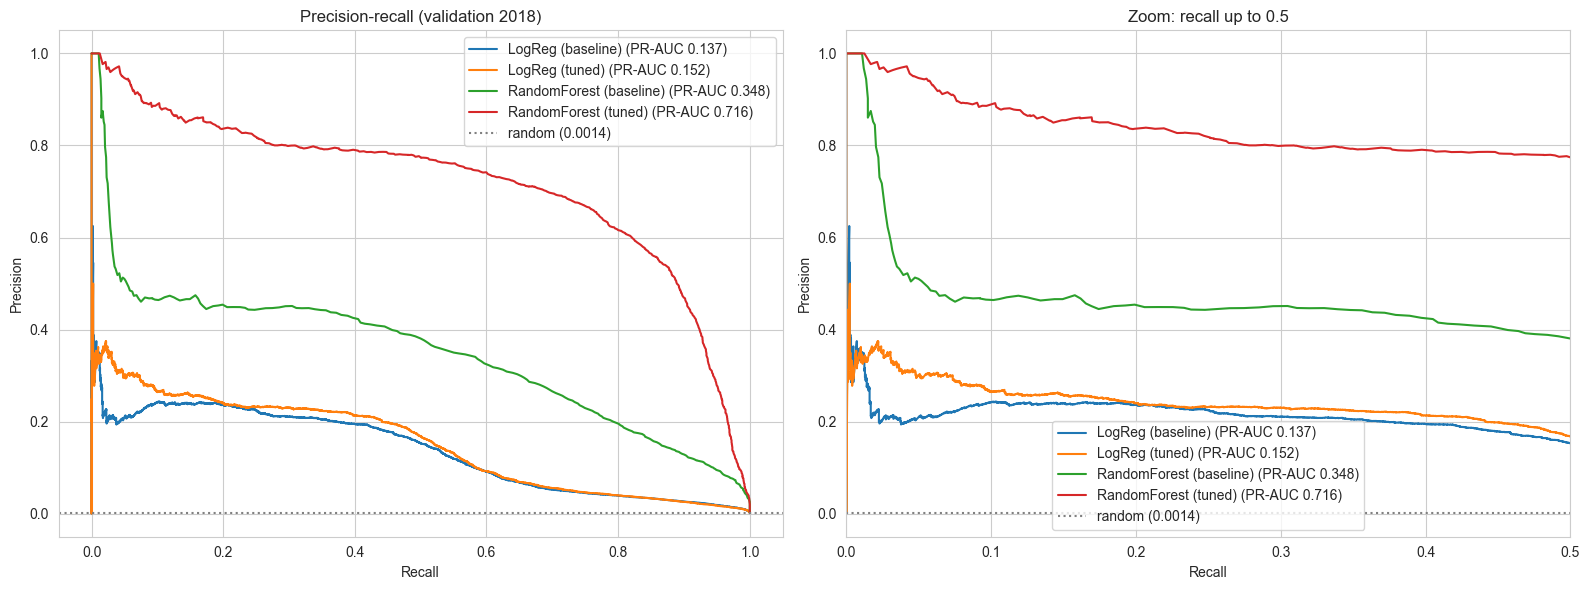

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
plot_pr_curves(y_val, val_scores, ax=axes[0])
plot_pr_curves(y_val, val_scores, ax=axes[1], title="Zoom: recall up to 0.5")
axes[1].set_xlim(0, 0.5)
plt.tight_layout()
plt.show()

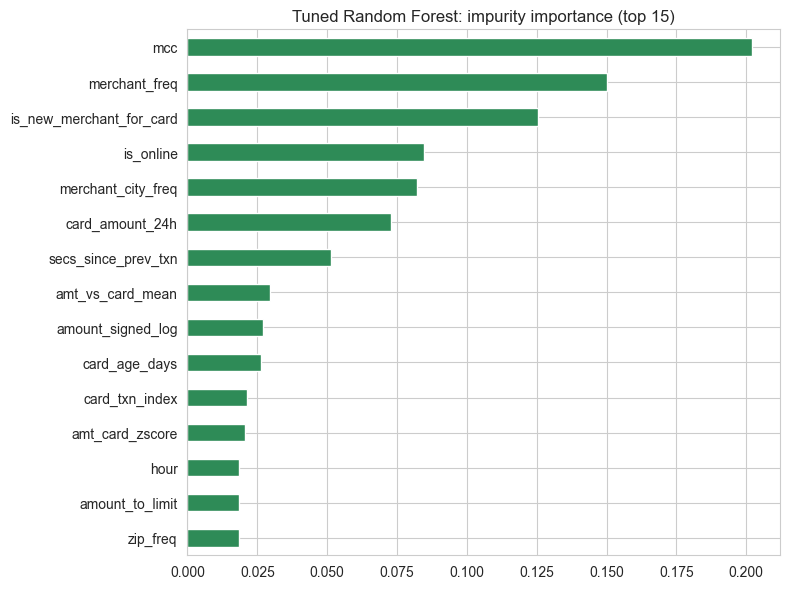

In [12]:
imp = pd.Series(rf_tuned.feature_importances_, index=FEATURES).sort_values()
imp.tail(15).plot(kind="barh", figsize=(8, 6), color="seagreen")
plt.title("Tuned Random Forest: impurity importance (top 15)")
plt.tight_layout()
plt.show()

## Findings

| Model | Val PR-AUC | Recall @ 50% precision | Top 0.1% alerts: precision / recall |
|---|---|---|---|
| LogReg baseline | 0.137 | 0.002 | 0.24 / 0.17 |
| LogReg tuned | 0.152 | 0.002 | 0.25 / 0.17 |
| Random Forest baseline | 0.348 | 0.052 | 0.45 / 0.31 |
| **Random Forest tuned** | **0.716** | **0.889** | **0.76 / 0.53** |

**ROC-AUC is the wrong metric here.** Logistic regression scores **0.98 ROC-AUC** but only **0.15 PR-AUC**, and it can't reach 50% precision at almost any recall. At a 0.145% fraud rate, ranking most frauds above most legitimate transactions is easy. Ranking them above the *few thousand riskiest* legitimate ones is what matters, and that's what PR-AUC measures.

**Tuning barely helps the linear model (+0.015).** Every top trial is L2 + balanced weights + the most non-frauds per fraud (50). The limit is the model form, not the settings: it can't capture interactions such as "online *and* new merchant *and* unusual amount".

**Tuning doubles the Random Forest (0.35 → 0.72),** and most of the gain comes from *which data* it trains on, not from tree settings:
- **`start_year = 2010`**: training only on 2010–2017 beats using all 27 years. Fraud patterns drift, and old fraud teaches the forest patterns that no longer hold in 2018. (Logistic regression preferred all years. A low-variance linear model benefits more from extra data than it suffers from drift.)
- **`neg_per_pos = 40`**: more non-fraud examples give a better picture of normal behavior.
- `max_features = 0.5`, deep trees (`max_depth = 30`, `min_samples_leaf = 1`): the forest wants complex trees.

**⚠️ The search may not have converged:**
- `start_year = 2010` and `neg_per_pos = 40` are both at the **edge** of the ranges searched, so later start years or more non-frauds might do better still.
- The best trial was the very last one, and TPE repeated some configurations (trials 23 and 24 are identical).
- The CatBoost phase should search wider ranges for these two data settings (e.g. start year up to 2015, up to 100 non-frauds per fraud).

**Context:** untuned CatBoost on the same features scored 0.73 in the feature-selection notebook. A tuned Random Forest roughly matches an *untuned* boosted model. The next phase shows how far tuning takes CatBoost.

**Reminder:** these are validation scores after 25 trials of selecting on validation, so they're optimistic. The honest comparison is the single 2019 test evaluation at the end.

## 4. Save

- Fitted tuned models go to `models/` (git-ignored, because they're large and reproducible from this notebook).
- Parameters, validation thresholds and metrics go to `reports/`, so the final-evaluation phase can score the 2019 test set with exactly these settings.

In [13]:
joblib.dump({"preprocessor": lr_tuned[0], "model": lr_tuned[1], "features": FEATURES},
            MODELS_DIR / "logreg_tuned.joblib")
joblib.dump({"model": rf_tuned, "features": FEATURES}, MODELS_DIR / "random_forest_tuned.joblib", compress=3)

summary = compare(results)
summary.to_csv(REPORTS_DIR / "val_metrics_traditional.csv")
(REPORTS_DIR / "best_params_traditional.json").write_text(json.dumps({
    name: {"params": best_params[key], "val_threshold": results[label]["threshold"]}
    for name, key, label in [("logreg", "logreg", "LogReg (tuned)"),
                             ("random_forest", "random_forest", "RandomForest (tuned)")]
}, indent=2, default=str))
pd.DataFrame(val_scores).astype("float32").to_parquet(PROJECT_ROOT / "data" / "cache" / "val_scores_traditional.parquet")
print("Saved models, params and validation metrics.")
summary

Saved models, params and validation metrics.


,pr_auc,roc_auc,recall@precision0.5,precision@top0.1%,recall@top0.1%,threshold,precision@threshold,recall@threshold,alerts@threshold
LogReg (baseline),0.1372,0.9826,0.0024,0.2410,0.1666,0.9829,0.1938,0.4183,5377.0
LogReg (tuned),0.1521,0.9825,0.0024,0.2515,0.1738,0.9787,0.2104,0.4287,5076.0
RandomForest (baseline),0.3476,0.9968,0.0518,0.4483,0.3099,0.6733,0.3807,0.4998,3270.0
RandomForest (tuned),0.7155,0.9990,0.8888,0.7648,0.5287,0.5780,0.6653,0.7563,2832.0
